In [4]:
#step1
#collecting data

import requests
import pandas as pd
from bs4 import BeautifulSoup
import time
wiki_url="https://en.wikipedia.org/wiki/List_of_alternative_R%26B_artists"
api_url="https://musicbrainz.org/ws/2/artist/"

wiki_headers={"User-Agent": "StudentMusicResearch/1.0 (educational project)"}
response=requests.get(
    wiki_url,
    headers=wiki_headers,
    timeout=20)
print("Status:", response.status_code)
response.raise_for_status()
soup=BeautifulSoup(response.text, "html.parser")
print("Page title:", soup.title.get_text(strip=True))

Status: 200
Page title: List of alternative R&B artists - Wikipedia


In [6]:
artists_heading=soup.find(id="Artists")
if artists_heading is None:
    raise ValueError("no artists section...")
artist_list=artists_heading.find_next("ul")
if artist_list is None:
    raise ValueError("no artists section...")
print("artists section found")

artists section found


In [9]:
from urllib.parse import urljoin
wiki_records=[]
for item in artist_list.find_all("li", recursive=False):
    link=item.find("a", href=True)
    if link:
        artist_name=link.get_text(" ", strip=True)
        artist_url=urljoin(
            wiki_url,
            link["href"])
        wiki_records.append({
            "Artist": artist_name,
            "Wikipedia_URL": artist_url})
df_wiki=pd.DataFrame(wiki_records)
print("artists:", len(df_wiki))
display(df_wiki.head(10))

artists: 88


,Artist,Wikipedia_URL
0,070 Shake,https://en.wikipedia.org/wiki/070_Shake
1,6lack,https://en.wikipedia.org/wiki/6lack
2,Aaliyah,https://en.wikipedia.org/wiki/Aaliyah
3,Abra,https://en.wikipedia.org/wiki/Abra_(singer)
4,Jhené Aiko,https://en.wikipedia.org/wiki/Jhené_Aiko
5,AlunaGeorge,https://en.wikipedia.org/wiki/AlunaGeorge
6,Anders,https://en.wikipedia.org/wiki/Anders_(singer)
7,Omar Apollo,https://en.wikipedia.org/wiki/Omar_Apollo
8,Autre Ne Veut,https://en.wikipedia.org/wiki/Autre_Ne_Veut
9,Erykah Badu,https://en.wikipedia.org/wiki/Erykah_Badu


In [10]:
df_wiki.to_csv(
    "rnb_wikipedia_raw.csv",
    index=False,
    encoding="utf-8-sig")

In [17]:
api_headers={"User-Agent": "SIS-RnB-Research/1.0"}
params={
    "query": 'artist:"SZA"',
    "fmt": "json",
    "limit": 5}
response=requests.get(
    api_url,
    params=params,
    headers=api_headers,
    timeout=20)
print("Status:", response.status_code)
response.raise_for_status()
data=response.json()
print("Artists:", len(data.get("artists", [])))
display(data.get("artists", [])[:2])

Status: 200
Artists: 2


[{'id': '272989c8-5535-492d-a25c-9f58803e027f',
  'type': 'Person',
  'type-id': 'b6e035f4-3ce9-331c-97df-83397230b0df',
  'score': 100,
  'gender-id': '93452b5a-a947-30c8-934f-6a4056b151c2',
  'name': 'SZA',
  'sort-name': 'SZA',
  'gender': 'female',
  'country': 'US',
  'area': {'id': '489ce91b-6658-3307-9877-795b68554c98',
   'type': 'Country',
   'type-id': '06dd0ae4-8c74-30bb-b43d-95dcedf961de',
   'name': 'United States',
   'sort-name': 'United States',
   'life-span': {'ended': None}},
  'begin-area': {'id': '759f9567-9107-40ef-a825-e57824a62e70',
   'type': 'City',
   'type-id': '6fd8f29a-3d0a-32fc-980d-ea697b69da78',
   'name': 'St. Louis',
   'sort-name': 'St. Louis',
   'life-span': {'ended': None}},
  'ipis': ['00687343408'],
  'isnis': ['000000044802241X'],
  'life-span': {'begin': '1989-11-08', 'ended': None},
  'aliases': [{'sort-name': 'Solana Rowe',
    'name': 'Solana Rowe',
    'locale': None,
    'type': None,
    'primary': None,
    'begin-date': None,
    'end-

In [21]:
artists=data.get("artists", [])
if artists:
    artist=artists[0]
    print("Name:", artist.get("name"))
    print("Country:", artist.get("country"))
    print("Type:", artist.get("type"))
    print("Start date:", artist.get("life-span", {}).get("begin"))
    print("Ended:", artist.get("life-span", {}).get("ended"))
    print("MusicBrainz ID:", artist.get("id"))
    print("Match score:", artist.get("score"))

Name: SZA
Country: US
Type: Person
Start date: 1989-11-08
Ended: None
MusicBrainz ID: 272989c8-5535-492d-a25c-9f58803e027f
Match score: 100


In [20]:
selected_artists=df_wiki["Artist"].head(20).tolist()
music_records=[]
for name in selected_artists:
    params={
        "query": f'artist:"{name}"',
        "fmt": "json",
        "limit": 10}
    try:
        response=requests.get(
            api_url,
            params=params,
            headers=api_headers,
            timeout=20)
        response.raise_for_status()
        results=response.json().get("artists", [])
        matches=[
            artist for artist in results
            if artist.get("name", "").casefold()==name.casefold()]
        if matches:
            artist=max(
                matches,
                key=lambda x: x.get("score", 0))
            music_records.append({
                "Wiki_Artist": name,
                "Artist": artist.get("name"),
                "MusicBrainz_ID": artist.get("id"),
                "Country": artist.get("country"),
                "Artist_Type": artist.get("type"),
                "Start_Date": artist.get("life-span", {}).get("begin"),
                "Ended": artist.get("life-span", {}).get("ended"),
                "Match_Score": artist.get("score")})
            print("Matched:", name)
        else:
            print("No match:", name)
    except requests.exceptions.RequestException as error:
        print("fail:", name, error)
    time.sleep(1.2)
print("matching records:", len(music_records))

fail: 070 Shake 503 Server Error: Service Temporarily Unavailable for url: https://musicbrainz.org/ws/2/artist/?query=artist%3A%22070+Shake%22&fmt=json&limit=10
Matched: 6lack
Matched: Aaliyah
Matched: Abra
Matched: Jhené Aiko
Matched: AlunaGeorge
No match: Anders
fail: Omar Apollo 503 Server Error: Service Temporarily Unavailable for url: https://musicbrainz.org/ws/2/artist/?query=artist%3A%22Omar+Apollo%22&fmt=json&limit=10
Matched: Autre Ne Veut
Matched: Erykah Badu
Matched: Banks
fail: Blackbear 503 Server Error: Service Temporarily Unavailable for url: https://musicbrainz.org/ws/2/artist/?query=artist%3A%22Blackbear%22&fmt=json&limit=10
Matched: Blood Orange
Matched: Jesse Boykins III
fail: Daniel Caesar 503 Server Error: Service Temporarily Unavailable for url: https://musicbrainz.org/ws/2/artist/?query=artist%3A%22Daniel+Caesar%22&fmt=json&limit=10
Matched: Alessia Cara
Matched: Alex Clare
Matched: D'Angelo
Matched: Daley
No match: Dean
matching records: 14


In [22]:
columns=[
    "Wiki_Artist",
    "Artist",
    "MusicBrainz_ID",
    "Country",
    "Artist_Type",
    "Start_Date",
    "Ended",
    "Match_Score"]
df_api=pd.DataFrame(music_records, columns=columns)
print("MusicBrainz dataset size:", df_api.shape)
df_api.head(10)

MusicBrainz dataset size: (14, 8)


,Wiki_Artist,Artist,MusicBrainz_ID,Country,Artist_Type,Start_Date,Ended,Match_Score
0,6lack,6LACK,07832b42-8826-4ab1-acd3-c49a2f595ffe,US,Person,1992-06-24,None,100
1,Aaliyah,Aaliyah,bc85da58-52d9-457d-ae8d-5d8d4ec870a9,US,Person,1979-01-16,True,100
2,Abra,ABRA,b7c20887-5042-451d-ac3c-772e25cbe9d8,US,Person,1989-03-30,None,100
3,Jhené Aiko,Jhené Aiko,ceb3f5b7-9f1a-430f-afbe-976fdcf30482,US,Person,1988-03-16,None,100
4,AlunaGeorge,AlunaGeorge,e9da3ed5-eb9a-4f70-a0ed-4e59e380601f,GB,Group,2009,None,100
5,Autre Ne Veut,Autre Ne Veut,ef971f23-57a5-4e4d-a757-37dbf3937ab5,US,Person,1982-04-20,None,100
6,Erykah Badu,Erykah Badu,321531fc-db73-4ffa-a959-61a61a2908c1,US,Person,1971-02-26,None,100
7,Banks,BANKS,faa28a33-5470-4b90-90c3-e71955d93a44,US,Person,1988-06-16,None,96
8,Blood Orange,Blood Orange,3d254f1e-7d18-431b-baeb-68e57695dfdb,GB,Person,1985-12-23,None,100
9,Jesse Boykins III,Jesse Boykins III,2fbc5d12-d30b-41ab-a5ce-042aa60fed38,US,Person,1985-02-20,None,100


In [23]:
df_api.to_csv(
    "rnb_musicbrainz_raw.csv",
    index=False,
    encoding="utf-8-sig")

In [40]:
#step2
#data cleaning
df_wiki=pd.read_csv("rnb_wikipedia_raw.csv")
df_api=pd.read_csv("rnb_musicbrainz_raw.csv")
print("wiki:")
display(df_wiki.head())
print("api:")
display(df_api.head())

print("wiki dataset shape:", df_wiki.shape)
print("api dataset shape:", df_api.shape)
print("\nwiki columns:")
print(df_wiki.columns.tolist())
print("\napi columns:")
print(df_api.columns.tolist())

print("\nwiki missing values:")
print(df_wiki.isnull().sum())
print("\napi missing values:")
print(df_api.isnull().sum())

wiki:


,Artist,Wikipedia_URL
0,070 Shake,https://en.wikipedia.org/wiki/070_Shake
1,6lack,https://en.wikipedia.org/wiki/6lack
2,Aaliyah,https://en.wikipedia.org/wiki/Aaliyah
3,Abra,https://en.wikipedia.org/wiki/Abra_(singer)
4,Jhené Aiko,https://en.wikipedia.org/wiki/Jhené_Aiko


api:


,Wiki_Artist,Artist,MusicBrainz_ID,Country,Artist_Type,Start_Date,Ended,Match_Score
0,6lack,6LACK,07832b42-8826-4ab1-acd3-c49a2f595ffe,US,Person,1992-06-24,NaN,100
1,Aaliyah,Aaliyah,bc85da58-52d9-457d-ae8d-5d8d4ec870a9,US,Person,1979-01-16,True,100
2,Abra,ABRA,b7c20887-5042-451d-ac3c-772e25cbe9d8,US,Person,1989-03-30,NaN,100
3,Jhené Aiko,Jhené Aiko,ceb3f5b7-9f1a-430f-afbe-976fdcf30482,US,Person,1988-03-16,NaN,100
4,AlunaGeorge,AlunaGeorge,e9da3ed5-eb9a-4f70-a0ed-4e59e380601f,GB,Group,2009,NaN,100


wiki dataset shape: (88, 2)
api dataset shape: (14, 8)

wiki columns:
['Artist', 'Wikipedia_URL']

api columns:
['Wiki_Artist', 'Artist', 'MusicBrainz_ID', 'Country', 'Artist_Type', 'Start_Date', 'Ended', 'Match_Score']

wiki missing values:
Artist           0
Wikipedia_URL    0
dtype: int64

api missing values:
Wiki_Artist        0
Artist             0
MusicBrainz_ID     0
Country            1
Artist_Type        1
Start_Date         1
Ended             13
Match_Score        0
dtype: int64


In [28]:
df_wiki=df_wiki.rename(columns={
    "Artist": "Artist_Name",
    "Wikipedia_URL": "Wikipedia_Link"})

df_api=df_api.rename(columns={
    "Wiki_Artist": "Wikipedia_Artist",
    "Artist": "Artist_Name",
    "MusicBrainz_ID": "MBID",
    "Artist_Type": "Type",
    "Start_Date": "Begin_Date",
    "Match_Score": "Search_Score"})
print("wiki columns:")
print(df_wiki.columns.tolist())
print("\napi columns:")
print(df_api.columns.tolist())

wiki columns:
['Artist_Name', 'Wikipedia_Link']

api columns:
['Wikipedia_Artist', 'Artist_Name', 'MBID', 'Country', 'Type', 'Begin_Date', 'Ended', 'Search_Score']


In [35]:
df_wiki["Artist_Name"]=(df_wiki["Artist_Name"].astype("string")
    .str.replace(r"\s+", " ", regex=True).str.strip())
df_api["Artist_Name"]=(df_api["Artist_Name"].astype("string")
    .str.replace(r"\s+", " ", regex=True).str.strip())
df_api["Wikipedia_Artist"]=(df_api["Wikipedia_Artist"].astype("string")
    .str.replace(r"\s+", " ", regex=True).str.strip())
print("Cleaned wiki:")
display(df_wiki[["Artist_Name"]].head())
print("Cleaned api:")
display(df_api[["Artist_Name"]].head())

Cleaned wiki:


,Artist_Name
0,070 Shake
1,6lack
2,Aaliyah
3,Abra
4,Jhené Aiko


Cleaned api:


,Artist_Name
0,6LACK
1,Aaliyah
2,ABRA
3,Jhené Aiko
4,AlunaGeorge


In [36]:
df_wiki=df_wiki.dropna(subset=["Artist_Name"]).copy()
df_api=df_api.dropna(subset=["Artist_Name"]).copy()

df_wiki=df_wiki[df_wiki["Artist_Name"] != ""].copy()
df_api=df_api[df_api["Artist_Name"] != ""].copy()

df_api["Country"]=df_api["Country"].fillna("Unknown")
df_api["Type"]=df_api["Type"].fillna("Unknown")

df_api["Begin_Date"]=df_api["Begin_Date"].fillna("")
print("Missing values after cleaning:")
print(df_api.isnull().sum())

Missing values after cleaning:
Wikipedia_Artist     0
Artist_Name          0
MBID                 0
Country              0
Type                 0
Begin_Date           0
Ended               13
Search_Score         0
Begin_Year           1
Artist_Key           0
dtype: int64


In [37]:
df_api["Search_Score"]=pd.to_numeric(
    df_api["Search_Score"],
    errors="coerce")

df_api["Begin_Date"]=df_api["Begin_Date"].astype("string")

df_api["Begin_Year"]=pd.to_numeric(
    df_api["Begin_Date"].str.extract(r"^(\d{4})",expand=False),errors="coerce").astype("Int64")

print("Dtypes:")
print(df_api.dtypes)
display(df_api[[
    "Artist_Name",
    "Begin_Date",
    "Begin_Year",
    "Search_Score"]].head())

Dtypes:
Wikipedia_Artist    string
Artist_Name         string
MBID                   str
Country                str
Type                   str
Begin_Date          string
Ended               object
Search_Score         int64
Begin_Year           Int64
Artist_Key          string
dtype: object


,Artist_Name,Begin_Date,Begin_Year,Search_Score
0,6LACK,1992-06-24,1992,100
1,Aaliyah,1979-01-16,1979,100
2,ABRA,1989-03-30,1989,100
3,Jhené Aiko,1988-03-16,1988,100
4,AlunaGeorge,2009,2009,100


In [38]:
df_wiki["Artist_Key"]=(df_wiki["Artist_Name"].str.casefold()
    .str.replace(r"\s+", " ", regex=True).str.strip())
df_api["Artist_Key"]=(df_api["Wikipedia_Artist"].str.casefold()
    .str.replace(r"\s+", " ", regex=True).str.strip())
print("wiki matching keys:")
display(df_wiki[["Artist_Name", "Artist_Key"]].head())
print("api matching keys:")
display(df_api[["Artist_Name", "Artist_Key"]].head())

wiki matching keys:


,Artist_Name,Artist_Key
0,070 Shake,070 shake
1,6lack,6lack
2,Aaliyah,aaliyah
3,Abra,abra
4,Jhené Aiko,jhené aiko


api matching keys:


,Artist_Name,Artist_Key
0,6LACK,6lack
1,Aaliyah,aaliyah
2,ABRA,abra
3,Jhené Aiko,jhené aiko
4,AlunaGeorge,alunageorge


In [39]:
df_wiki.to_csv(
    "rnb_wikipedia_clean.csv",
    index=False,
    encoding="utf-8-sig")
df_api.to_csv(
    "rnb_musicbrainz_clean.csv",
    index=False,
    encoding="utf-8-sig")

In [42]:
#step3
#merging
df_wiki=pd.read_csv("rnb_wikipedia_clean.csv")
df_api=pd.read_csv("rnb_musicbrainz_clean.csv")

print("wiki columns:")
print(df_wiki.columns.tolist())
print("\napi columns:")
print(df_api.columns.tolist())
print("\nwiki records:", len(df_wiki))
print("api records:", len(df_api))

wiki columns:
['Artist_Name', 'Wikipedia_Link', 'Artist_Key']

api columns:
['Wikipedia_Artist', 'Artist_Name', 'MBID', 'Country', 'Type', 'Begin_Date', 'Ended', 'Search_Score', 'Begin_Year', 'Artist_Key']

wiki records: 88
api records: 14


In [43]:
df_wiki["Artist_Key"]=(df_wiki["Artist_Key"].astype("string").str.casefold().str.strip())
df_api["Artist_Key"]=(df_api["Artist_Key"].astype("string").str.casefold().str.strip())

df_wiki=df_wiki.dropna(subset=["Artist_Key"])
df_api=df_api.dropna(subset=["Artist_Key"])

df_wiki=df_wiki[df_wiki["Artist_Key"]!=""].copy()
df_api=df_api[df_api["Artist_Key"]!=""].copy()

In [48]:
df_merged=pd.merge(
    df_wiki,
    df_api.drop(columns=["Artist_Name"]),
    on="Artist_Key",
    how="left",
    indicator=True,
    validate="one_to_one")
print("Merged df:")
display(df_merged.head(10))
print("\nMerged df shape:", df_merged.shape)

Merged df:


,Artist_Name,Wikipedia_Link,Artist_Key,Wikipedia_Artist,MBID,Country,Type,Begin_Date,Ended,Search_Score,Begin_Year,_merge
0,070 Shake,https://en.wikipedia.org/wiki/070_Shake,070 shake,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
1,6lack,https://en.wikipedia.org/wiki/6lack,6lack,6lack,07832b42-8826-4ab1-acd3-c49a2f595ffe,US,Person,1992-06-24,NaN,100.0,1992.0,both
2,Aaliyah,https://en.wikipedia.org/wiki/Aaliyah,aaliyah,Aaliyah,bc85da58-52d9-457d-ae8d-5d8d4ec870a9,US,Person,1979-01-16,True,100.0,1979.0,both
3,Abra,https://en.wikipedia.org/wiki/Abra_(singer),abra,Abra,b7c20887-5042-451d-ac3c-772e25cbe9d8,US,Person,1989-03-30,NaN,100.0,1989.0,both
4,Jhené Aiko,https://en.wikipedia.org/wiki/Jhené_Aiko,jhené aiko,Jhené Aiko,ceb3f5b7-9f1a-430f-afbe-976fdcf30482,US,Person,1988-03-16,NaN,100.0,1988.0,both
5,AlunaGeorge,https://en.wikipedia.org/wiki/AlunaGeorge,alunageorge,AlunaGeorge,e9da3ed5-eb9a-4f70-a0ed-4e59e380601f,GB,Group,2009,NaN,100.0,2009.0,both
6,Anders,https://en.wikipedia.org/wiki/Anders_(singer),anders,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
7,Omar Apollo,https://en.wikipedia.org/wiki/Omar_Apollo,omar apollo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
8,Autre Ne Veut,https://en.wikipedia.org/wiki/Autre_Ne_Veut,autre ne veut,Autre Ne Veut,ef971f23-57a5-4e4d-a757-37dbf3937ab5,US,Person,1982-04-20,NaN,100.0,1982.0,both
9,Erykah Badu,https://en.wikipedia.org/wiki/Erykah_Badu,erykah badu,Erykah Badu,321531fc-db73-4ffa-a959-61a61a2908c1,US,Person,1971-02-26,NaN,100.0,1971.0,both



Merged df shape: (88, 12)


In [57]:
df_merged=df_merged[[
    "Artist_Name",
    "Wikipedia_Link",
    "MBID",
    "Country",
    "Type",
    "Begin_Date",
    "Begin_Year",
    "Ended",
    "Search_Score",
    "Match_Status"]].copy()
df_merged=df_merged.rename(columns={
    "Match_Status": "Match_Status"})
display(df_merged.head(10))

,Artist_Name,Wikipedia_Link,MBID,Country,Type,Begin_Date,Begin_Year,Ended,Search_Score,Match_Status
0,070 Shake,https://en.wikipedia.org/wiki/070_Shake,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
1,6lack,https://en.wikipedia.org/wiki/6lack,07832b42-8826-4ab1-acd3-c49a2f595ffe,US,Person,1992-06-24,1992.0,NaN,100.0,both
2,Aaliyah,https://en.wikipedia.org/wiki/Aaliyah,bc85da58-52d9-457d-ae8d-5d8d4ec870a9,US,Person,1979-01-16,1979.0,True,100.0,both
3,Abra,https://en.wikipedia.org/wiki/Abra_(singer),b7c20887-5042-451d-ac3c-772e25cbe9d8,US,Person,1989-03-30,1989.0,NaN,100.0,both
4,Jhené Aiko,https://en.wikipedia.org/wiki/Jhené_Aiko,ceb3f5b7-9f1a-430f-afbe-976fdcf30482,US,Person,1988-03-16,1988.0,NaN,100.0,both
5,AlunaGeorge,https://en.wikipedia.org/wiki/AlunaGeorge,e9da3ed5-eb9a-4f70-a0ed-4e59e380601f,GB,Group,2009,2009.0,NaN,100.0,both
6,Anders,https://en.wikipedia.org/wiki/Anders_(singer),NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
7,Omar Apollo,https://en.wikipedia.org/wiki/Omar_Apollo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
8,Autre Ne Veut,https://en.wikipedia.org/wiki/Autre_Ne_Veut,ef971f23-57a5-4e4d-a757-37dbf3937ab5,US,Person,1982-04-20,1982.0,NaN,100.0,both
9,Erykah Badu,https://en.wikipedia.org/wiki/Erykah_Badu,321531fc-db73-4ffa-a959-61a61a2908c1,US,Person,1971-02-26,1971.0,NaN,100.0,both


In [59]:
df_merged.to_csv(
    "rnb_merged.csv",
    index=False,
    encoding="utf-8-sig")

In [62]:
#step4
#analysis
import numpy as np
df=pd.read_csv("rnb_merged.csv")
print("df size:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDtypes:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate artists:")
print(df["Artist_Name"].duplicated().sum())

df size: (88, 10)

Column names:
['Artist_Name', 'Wikipedia_Link', 'MBID', 'Country', 'Type', 'Begin_Date', 'Begin_Year', 'Ended', 'Search_Score', 'Match_Status']

Dtypes:
Artist_Name           str
Wikipedia_Link        str
MBID                  str
Country               str
Type                  str
Begin_Date            str
Begin_Year        float64
Ended              object
Search_Score      float64
Match_Status          str
dtype: object

Missing values:
Artist_Name        0
Wikipedia_Link     0
MBID              74
Country           74
Type              74
Begin_Date        75
Begin_Year        75
Ended             87
Search_Score      74
Match_Status       0
dtype: int64

Duplicate artists:
0


In [70]:
df_matched=df[df["Match_Status"]=="both"].copy()
print("Matched dataset size:", df_matched.shape)
display(df_matched.head())

Matched dataset size: (14, 10)


,Artist_Name,Wikipedia_Link,MBID,Country,Type,Begin_Date,Begin_Year,Ended,Search_Score,Match_Status
1,6lack,https://en.wikipedia.org/wiki/6lack,07832b42-8826-4ab1-acd3-c49a2f595ffe,US,Person,1992-06-24,1992.0,NaN,100.0,both
2,Aaliyah,https://en.wikipedia.org/wiki/Aaliyah,bc85da58-52d9-457d-ae8d-5d8d4ec870a9,US,Person,1979-01-16,1979.0,True,100.0,both
3,Abra,https://en.wikipedia.org/wiki/Abra_(singer),b7c20887-5042-451d-ac3c-772e25cbe9d8,US,Person,1989-03-30,1989.0,NaN,100.0,both
4,Jhené Aiko,https://en.wikipedia.org/wiki/Jhené_Aiko,ceb3f5b7-9f1a-430f-afbe-976fdcf30482,US,Person,1988-03-16,1988.0,NaN,100.0,both
5,AlunaGeorge,https://en.wikipedia.org/wiki/AlunaGeorge,e9da3ed5-eb9a-4f70-a0ed-4e59e380601f,GB,Group,2009,2009.0,NaN,100.0,both


In [71]:
df_matched["Begin_Year"]=pd.to_numeric(
    df_matched["Begin_Year"],errors="coerce")
df_matched["Search_Score"]=pd.to_numeric(
    df_matched["Search_Score"],errors="coerce")
print("Desc. stats:")
display(df_matched[["Begin_Year", "Search_Score"]].describe())

Desc. stats:


,Begin_Year,Search_Score
count,13.000000,14.000000
mean,1987.615385,97.857143
std,8.893241,6.137616
min,1971.000000,77.000000
25%,1985.000000,100.000000
50%,1988.000000,100.000000
75%,1989.000000,100.000000
max,2009.000000,100.000000


In [72]:
country_counts=(df_matched["Country"].fillna("Unknown").value_counts())
print("Artists by country:")
display(country_counts.to_frame("Number_of_Artists"))

Artists by country:


,Number_of_Artists
Country,
US,8
GB,4
CA,1
Unknown,1


In [73]:
country_type_table=pd.crosstab(df_matched["Country"].fillna("Unknown"),
    df_matched["Type"].fillna("Unknown"))
print("Country and artist type comparison:")
display(country_type_table)

Country and artist type comparison:


Type,Group,Person,Unknown
Country,,,
CA,0,1,0
GB,1,3,0
US,0,8,0
Unknown,0,0,1


In [76]:
corr_data=df_matched[df_matched["Type"]=="Person"][["Begin_Year", "Search_Score"]].dropna()
print("records:", len(correlation_data))
display(corr_data.head())

records: 12


,Begin_Year,Search_Score
1,1992.0,100.0
2,1979.0,100.0
3,1989.0,100.0
4,1988.0,100.0
8,1982.0,100.0


In [77]:
if(
    len(corr_data)>=3
    and corr_data["Begin_Year"].nunique() > 1
    and corr_data["Search_Score"].nunique() > 1):
    correlation=corr_data.corr(method="pearson")
    print("Corr matrix:")
    display(correlation)
else:
    print("Insufficient variation or records "
        "for meaningful correlation calculation.")

Corr matrix:


,Begin_Year,Search_Score
Begin_Year,1.000000,-0.186492
Search_Score,-0.186492,1.000000


In [80]:
summary=pd.DataFrame({
    "Metric": [
        "Total Wikipedia artists",
        "Matched MusicBrainz artists",
        "Unmatched artists",
        "Countries represented",
        "Individual artists",
        "Musical groups"],
    "Value": [
        len(df),
        len(df_matched),
        len(df)-len(df_matched),
        df_matched["Country"].dropna().nunique(),(df_matched["Type"]=="Person").sum(),(df_matched["Type"]=="Group").sum()]})
display(summary)

,Metric,Value
0,Total Wikipedia artists,88
1,Matched MusicBrainz artists,14
2,Unmatched artists,74
3,Countries represented,4
4,Individual artists,12
5,Musical groups,1


In [81]:
summary.to_csv(
    "rnb_eda_summary.csv",
    index=False,
    encoding="utf-8-sig")
country_type_table.to_csv(
    "rnb_country_type_analysis.csv",
    encoding="utf-8-sig")

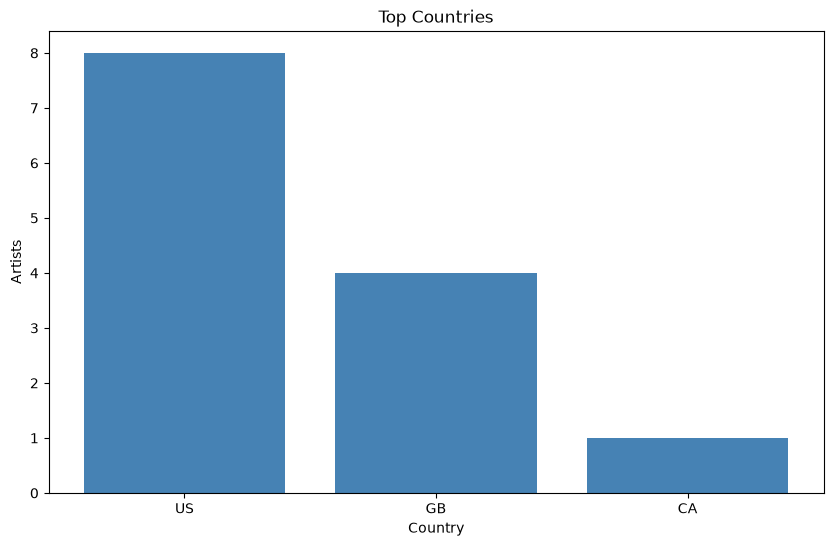

In [86]:
#step5
#visual
import matplotlib.pyplot as plt
df=pd.read_csv("rnb_merged.csv")
df_matched=df[df["Match_Status"]=="both"].copy()
df_matched["Begin_Year"]=pd.to_numeric(df_matched["Begin_Year"],errors="coerce")

country_counts=(df_matched["Country"].dropna())
country_counts=country_counts[country_counts!="Unknown"].value_counts().head(10)
if not country_counts.empty:
    plt.figure(figsize=(10, 6))
    plt.bar(
        country_counts.index,
        country_counts.values,
        color="steelblue")
    plt.title("Top Countries")
    plt.xlabel("Country")
    plt.ylabel("Artists")
    plt.show()
else:
    print("No data available...")

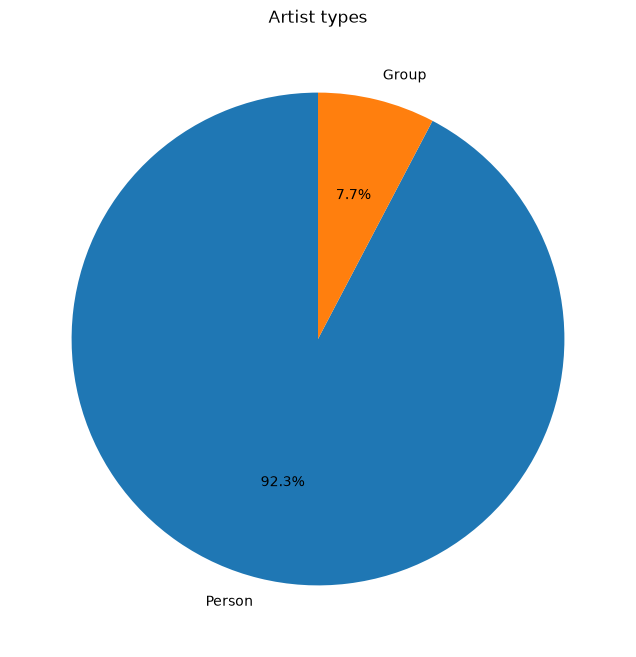

In [89]:
type_counts=(df_matched["Type"].dropna())
type_counts=type_counts[type_counts!="Unknown"].value_counts()
if not type_counts.empty:
    plt.figure(figsize=(8, 8))
    plt.pie(
        type_counts.values,
        labels=type_counts.index,
        autopct="%1.1f%%",
        startangle=90)
    plt.title("Artist types")
    plt.show()
else:
    print("No data available...")

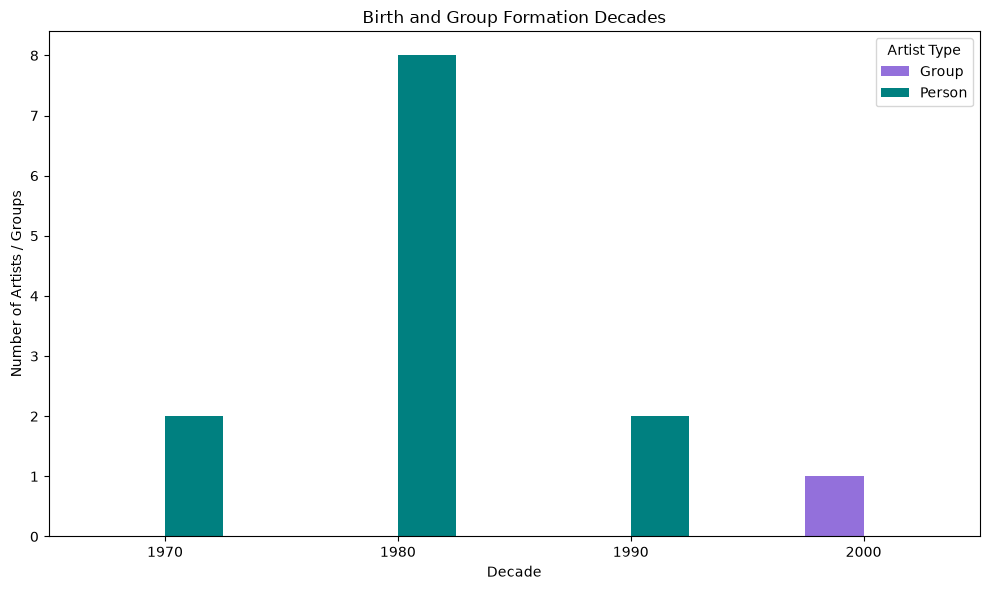

In [95]:
df_decades=df_matched[df_matched["Type"].isin(["Person", "Group"])].copy()
df_decades=df_decades.dropna(subset=["Begin_Year"])
df_decades["Decade"]=(df_decades["Begin_Year"]//10*10).astype(int)
decade_counts=pd.crosstab(df_decades["Decade"],df_decades["Type"])

if not decade_counts.empty:
    ax=decade_counts.plot(
        kind="bar",
        figsize=(10, 6),
        color=["mediumpurple", "teal"][:len(decade_counts.columns)])
    plt.title("Birth and Group Formation Decades")
    plt.xlabel("Decade")
    plt.ylabel("Number of Artists / Groups")
    plt.xticks(rotation=0)
    plt.legend(title="Artist Type")
    plt.tight_layout()
    plt.show()
else:
    print("No data available...")

In [98]:
df.to_csv(
    "rnb_final_dataset.csv",
    index=False,
    encoding="utf-8-sig")